
# SWYNEX Final Data Science Project

## Titanic Survival Prediction

### 1. Project Overview

This project focuses on predicting passenger survival
during the Titanic disaster using machine learning.

The project covers:
- Problem Statement
- Data Collection
- Data Preparation
- Exploratory Data Analysis (EDA)
- Model Building
- Model Evaluation
- Conclusion

### 2. Problem Statement

The Titanic disaster resulted in the loss of many lives.
The objective of this project is to analyze passenger
information and build a machine learning model that
predicts whether a passenger survived or not.

### 3. Dataset Description

Dataset: Titanic Dataset

Source: Kaggle

Target Variable: Survived

0 = Did Not Survive
1 = Survived

### 4. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook


In [1]:
import pandas as pd 
import numpy as np 
df= pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:

# Check dataset information
df.info()

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Fill missing Age values
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked values
df['Embarked'] = df['Embarked'].fillna(
    df['Embarked'].mode()[0]
)

# Drop Cabin column
df = df.drop(columns=['Cabin'])

# Verify cleaned dataset
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [3]:

# Save cleaned dataset
df.to_csv("cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully!")



Cleaned dataset saved successfully!



## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand
patterns, relationships and trends in the Titanic dataset.

The analysis focuses on:
- Overall survival distribution
- Gender and survival
- Passenger class and survival
- Age and survival
- Fare and survival
- Embarkation port and survival
- Correlation between numerical features


In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


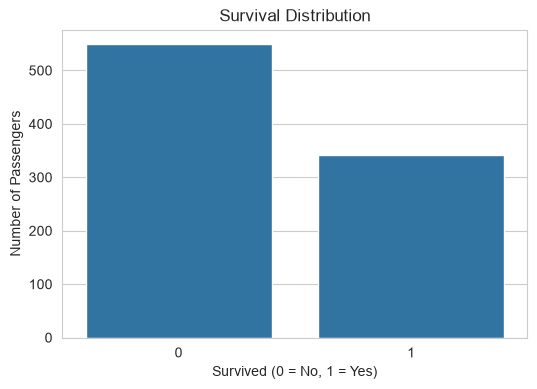

In [5]:

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Survived')
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


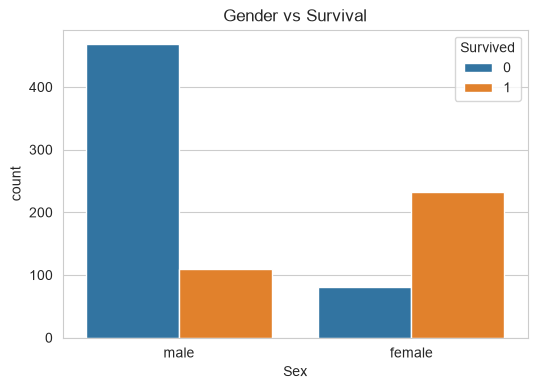

In [6]:

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Sex', hue='Survived')
plt.title("Gender vs Survival")
plt.show()


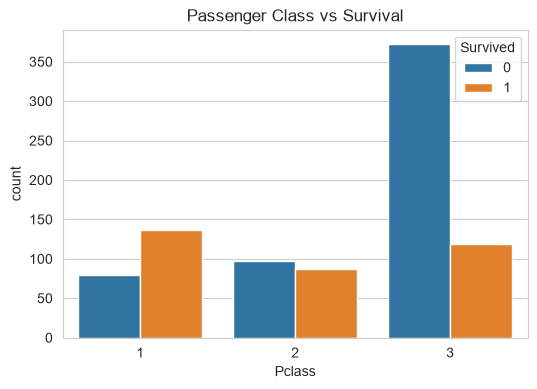

In [7]:

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Pclass', hue='Survived')
plt.title("Passenger Class vs Survival")
plt.show()


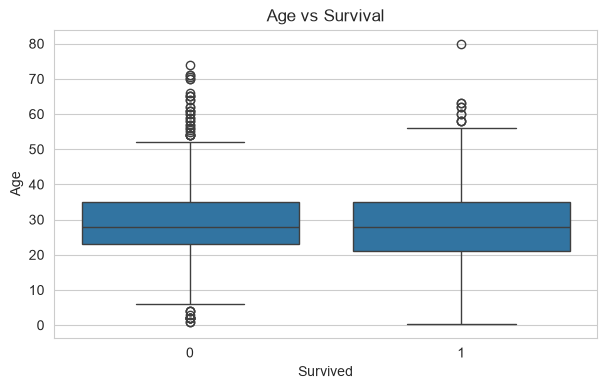

In [8]:

plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='Survived', y='Age')
plt.title("Age vs Survival")
plt.show()


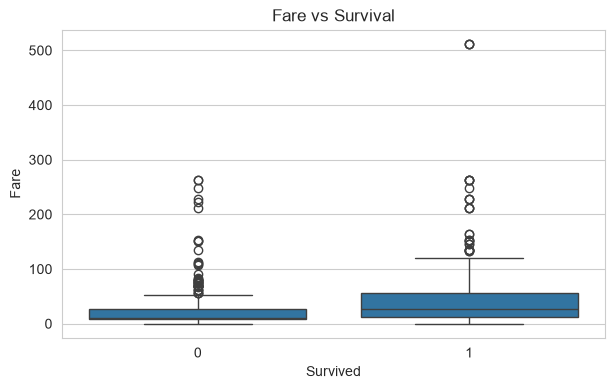

In [9]:

plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='Survived', y='Fare')
plt.title("Fare vs Survival")
plt.show()


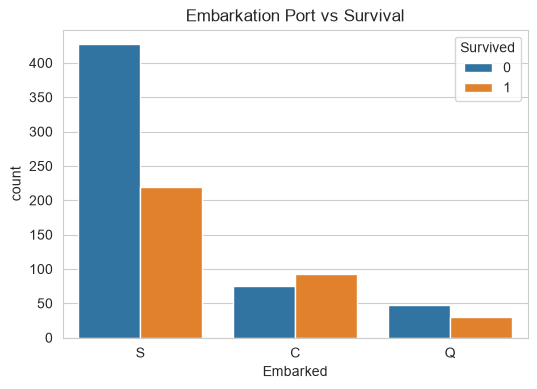

In [10]:

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Embarked', hue='Survived')
plt.title("Embarkation Port vs Survival")
plt.show()


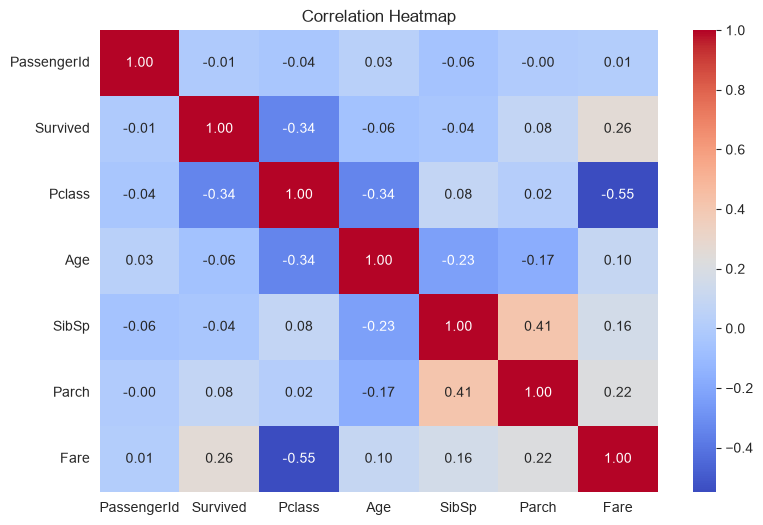

In [11]:

plt.figure(figsize=(9,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()



## 7. Key Findings and Insights

1. Female passengers had a significantly higher survival rate than male passengers.

2. First-class passengers had better survival chances compared to second and third-class passengers.

3. Age analysis showed differences in survival patterns between children and adults.

4. Passengers who paid higher fares generally had better survival chances.

5. Survival rates varied across different embarkation ports.

6. Passenger class and fare showed relationships with survival.

These findings indicate that gender, passenger class,
age and fare are important features for predicting survival.



## 8. Model Building

Machine Learning is used to predict passenger survival
based on passenger characteristics.

This project uses Logistic Regression, a supervised
machine learning classification algorithm.

### Selected Model: Logistic Regression

The model predicts:
- 0 – Passenger did not survive
- 1 – Passenger survived

An 80:20 train-test split is used for model training
and evaluation.


In [12]:

# Select important features
X = df[['Pclass', 'Sex', 'Age', 'SibSp',
        'Parch', 'Fare', 'Embarked']]

# Target variable
y = df['Survived']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (891, 7)
Target Shape: (891,)


In [13]:

# Convert categorical variables into numerical values
X = pd.get_dummies(
    X,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

X.head()


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,1,0,1
1,1,38.0,1,0,71.2833,0,0,0
2,3,26.0,0,0,7.9250,0,0,1
3,1,35.0,1,0,53.1000,0,0,1
4,3,35.0,0,0,8.0500,1,0,1


In [14]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (712, 8)
Testing Data: (179, 8)


In [15]:

from sklearn.linear_model import LogisticRegression

# Initialize model
model = LogisticRegression(max_iter=1000)

# Train model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [16]:

# Predict survival
y_pred = model.predict(X_test)

print("Predictions:", y_pred[:10])


Predictions: [0 0 0 0 1 0 1 0 0 0]



## 9. Model Evaluation

Model evaluation measures the performance of a trained
machine learning model.

The following evaluation metrics are used:

1. Accuracy
2. Precision
3. Recall
4. F1-Score
5. Confusion Matrix


In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Evaluation Results
------------------------
Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1-Score: 0.7244

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



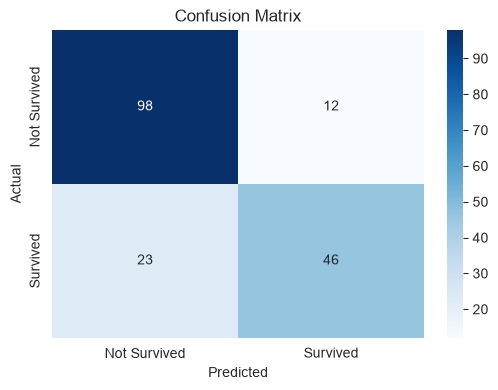

In [18]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()



### Evaluation Interpretation

The model was evaluated using accuracy, precision,
recall and F1-score.

- Accuracy measures overall correct predictions.
- Precision measures how many predicted survivors
  actually survived.
- Recall measures how many actual survivors were
  correctly identified.
- F1-score balances precision and recall.

The confusion matrix provides a visual representation
of correct and incorrect predictions.



## 10. Limitations of the Project

Although the Logistic Regression model provides useful
predictions, the project has some limitations:

1. The dataset contains a limited number of passenger records.
2. Some passenger information is missing.
3. Logistic Regression may not capture complex relationships
   between features.
4. The model is trained and evaluated on a single train-test split.
5. Historical Titanic data may not represent all real-world
   survival situations.

Future improvements could include testing advanced models
such as Random Forest and Decision Tree.



## 10. Limitations of the Project

Although the Logistic Regression model provides useful
predictions, the project has some limitations:

1. The dataset contains a limited number of passenger records.
2. Some passenger information is missing.
3. Logistic Regression may not capture complex relationships
   between features.
4. The model is trained and evaluated on a single train-test split.
5. Historical Titanic data may not represent all real-world
   survival situations.

Future improvements could include testing advanced models
such as Random Forest and Decision Tree.


In [19]:
df['Fare'] = df['Fare'].fillna(df['Fare'].median())